In [1]:
import pandas as pd

# Load the IBM Telco Customer Churn dataset
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

# Display the first five rows
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

print("Number of customers:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset shape: (7043, 21)
Number of customers: 7043
Number of columns: 21


In [3]:

# Display information about the dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:

# Check for missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())

# Check for blank spaces in TotalCharges
print("\nBlank values in TotalCharges:")
print((df["TotalCharges"].str.strip() == "").sum())


Missing values in each column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank values in TotalCharges:
11


In [5]:

# Check for duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

# Check for duplicate customer IDs
print("Number of duplicate customer IDs:", df["customerID"].duplicated().sum())


Number of duplicate rows: 0
Number of duplicate customer IDs: 0


In [6]:

# Count customers who churned and did not churn
print("Churn distribution:")
print(df["Churn"].value_counts())

# Calculate the percentage of each class
print("\nChurn percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)


Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


Summary statistics:
            tenure  MonthlyCharges
count  7043.000000     7043.000000
mean     32.371149       64.761692
std      24.559481       30.090047
min       0.000000       18.250000
25%       9.000000       35.500000
50%      29.000000       70.350000
75%      55.000000       89.850000
max      72.000000      118.750000


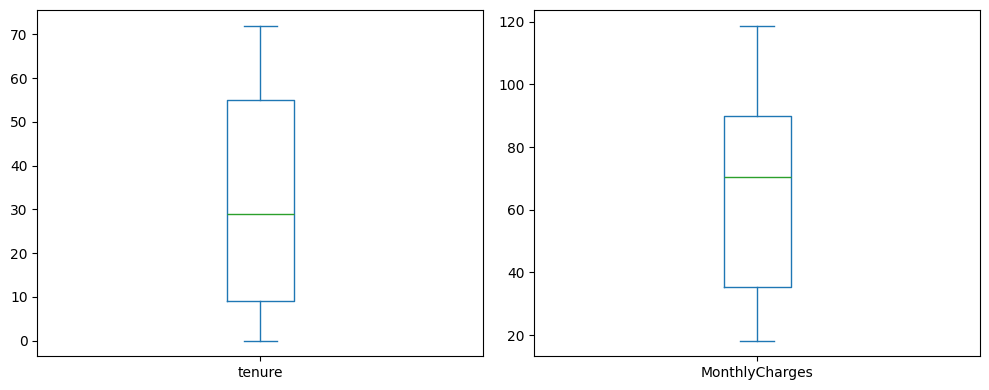

In [7]:

# Display summary statistics for numerical columns
print("Summary statistics:")
print(df[["tenure", "MonthlyCharges"]].describe())

# Create boxplots to check for outliers
import matplotlib.pyplot as plt

df[["tenure", "MonthlyCharges"]].plot(
    kind="box",
    subplots=True,
    figsize=(10, 4)
)

plt.tight_layout()
plt.show()


In [8]:

# Check maximum values
print("Maximum values:")
print(df[["tenure", "MonthlyCharges"]].max())

# Count potential outliers using the IQR method
for column in ["tenure", "MonthlyCharges"]:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    print(f"{column}: {outliers} potential outliers")


Maximum values:
tenure             72.00
MonthlyCharges    118.75
dtype: float64
tenure: 0 potential outliers
MonthlyCharges: 0 potential outliers


In [9]:

# Convert TotalCharges from text to numbers
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check the new data type
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

# Count missing values after conversion
print("\nMissing TotalCharges values:")
print(df["TotalCharges"].isnull().sum())

# Display summary statistics
print("\nTotalCharges statistics:")
print(df["TotalCharges"].describe())


TotalCharges data type:
float64

Missing TotalCharges values:
11

TotalCharges statistics:
count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


In [18]:
# Check for outliers in TotalCharges using the IQR method
Q1 = df["TotalCharges"].quantile(0.25)
Q3 = df["TotalCharges"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["TotalCharges"] < lower_bound) |
    (df["TotalCharges"] > upper_bound)
]

print("TotalCharges outliers:", len(outliers))
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

TotalCharges outliers: 0
Lower bound: -4688.481250000001
Upper bound: 8884.66875


In [10]:

# Find customers with missing TotalCharges
missing_customers = df[df["TotalCharges"].isnull()]

# Display their tenure, monthly charges and churn
print(missing_customers[
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
])

# Check how many missing-value customers have zero tenure
print("\nCustomers with zero tenure:")
print((missing_customers["tenure"] == 0).sum())


      tenure  MonthlyCharges  TotalCharges Churn
488        0           52.55           NaN    No
753        0           20.25           NaN    No
936        0           80.85           NaN    No
1082       0           25.75           NaN    No
1340       0           56.05           NaN    No
3331       0           19.85           NaN    No
3826       0           25.35           NaN    No
4380       0           20.00           NaN    No
5218       0           19.70           NaN    No
6670       0           73.35           NaN    No
6754       0           61.90           NaN    No

Customers with zero tenure:
11


## Data Audit Summary

The IBM Telco Customer Churn dataset contains 7,043 customer records and 21 columns.

**Missing values:** The initial missing-value check showed no missing values. However, after converting `TotalCharges` into a numerical column, 11 missing values were identified. All 11 customers had a tenure of zero months. These missing values will be handled using median imputation in the preprocessing pipeline.

**Duplicate records:** No duplicate rows or duplicate customer IDs were found.

**Class distribution:** Approximately 73.46% of customers did not churn, while 26.54% churned. This shows that the dataset is imbalanced, so accuracy alone is not enough to evaluate model performance.

**Numerical features:** The numerical features examined were `tenure`, `MonthlyCharges` and `TotalCharges`. The IQR method was used to check for outliers, and no outliers were identified in any of these three features. The average customer tenure was approximately 32.37 months, and the average monthly charge was approximately 64.76. The average total charge was approximately 2,283.30.

**Data preparation:** The `Churn` target was converted into binary values, with 0 representing customers who stayed and 1 representing customers who left. The `customerID` column was excluded because it is an identifier rather than a useful predictive feature.

In [11]:

# Convert Churn from Yes/No into 1/0
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Check the updated values
print("Churn values after conversion:")
print(df["Churn"].value_counts())

# Check the data type
print("\nChurn data type:")
print(df["Churn"].dtype)


Churn values after conversion:
Churn
0    5174
1    1869
Name: count, dtype: int64

Churn data type:
int64


In [12]:

# Separate input features from the target variable

X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"]

# Check the shapes
print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

# Display the input feature names
print("\nInput features:")
print(X.columns.tolist())


Input features shape: (7043, 19)
Target variable shape: (7043,)

Input features:
['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']


In [13]:

# Import the function for splitting data
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the sizes of each set
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)


Training features: (5634, 19)
Testing features: (1409, 19)
Training labels: (5634,)
Testing labels: (1409,)


In [14]:

# Import preprocessing tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numerical_features
]

# Pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical features:", numerical_features)
print("Number of categorical features:", len(categorical_features))


Preprocessing pipeline created successfully!
Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of categorical features: 16


## Preprocessing and Train/Test Split

The dataset was divided into 80% training data and 20% testing data using `train_test_split` with `random_state=42`.

Stratified sampling was used to maintain approximately the same proportion of churned and non-churned customers in both sets.

The training set contains 5,634 records, and the test set contains 1,409 records.

**Numerical features:** The numerical columns are `tenure`, `MonthlyCharges` and `TotalCharges`. Missing values are handled using median imputation, and the numerical features are standardised using `StandardScaler`.

**Categorical features:** Missing values are handled using the most frequent category, and categorical values are converted into numerical features using `OneHotEncoder`.

These preprocessing steps are defined in a `ColumnTransformer` so that numerical and categorical columns are handled appropriately.

The preprocessing transformer has not yet been fitted. In later model training, it will be fitted using only the training data to avoid data leakage. The test set will be kept separate for final evaluation.

In [15]:

# Import the baseline classifier
from sklearn.dummy import DummyClassifier

# Create the baseline model
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the baseline model
baseline_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_baseline = baseline_model.predict(X_test)

# Display the first 10 predictions
print("First 10 baseline predictions:")
print(y_pred_baseline[:10])

print("\nBaseline model trained successfully!")


First 10 baseline predictions:
[0 0 0 0 0 0 0 0 0 0]

Baseline model trained successfully!


In [16]:

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Calculate baseline evaluation metrics
accuracy = accuracy_score(y_test, y_pred_baseline)

precision = precision_score(
    y_test, y_pred_baseline, zero_division=0
)

recall = recall_score(
    y_test, y_pred_baseline, zero_division=0
)

f1 = f1_score(
    y_test, y_pred_baseline, zero_division=0
)

# Get the baseline model's predicted probabilities
y_prob_baseline = baseline_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob_baseline)

# Display results
print("Baseline Model Evaluation Results")
print("---------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))


Baseline Model Evaluation Results
---------------------------------
Accuracy:  0.7346
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
ROC-AUC:   0.5000

Confusion Matrix:
[[1035    0]
 [ 374    0]]


In [17]:

# Create a table containing baseline results
baseline_results = pd.DataFrame({
    "Model": ["Dummy Classifier (Baseline)"],
    "Accuracy": [accuracy],
    "Precision": [precision],
    "Recall": [recall],
    "F1-score": [f1],
    "ROC-AUC": [roc_auc]
})

# Display the results table
print("Baseline Model Results:")
display(baseline_results)

# Save results as a CSV file
baseline_results.to_csv(
    "baseline_results.csv",
    index=False
)

print("Baseline results saved successfully!")


Baseline Model Results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Dummy Classifier (Baseline),0.734564,0.0,0.0,0.0,0.5


Baseline results saved successfully!


## Baseline Model Evaluation

A `DummyClassifier` using the `most_frequent` strategy was trained to establish a baseline for the customer churn prediction task.

This model always predicts the most common class in the training data, which is `Churn = 0` (customer stayed).

The baseline achieved an accuracy of approximately 73.46%. However, its precision, recall and F1-score for the churn class were all zero because it did not identify any customers who actually churned.

The ROC-AUC score was 0.50, indicating that the baseline model has no ability to distinguish between customers who churn and those who stay.

The confusion matrix showed that 1,035 non-churning customers were correctly classified, while all 374 churning customers were incorrectly classified as non-churning.

**Conclusion:** Accuracy alone is misleading for this imbalanced dataset. Future machine learning models should aim to improve recall, F1-score and ROC-AUC while maintaining reasonable precision.

The baseline provides a reference point for comparing more advanced models in Milestone 3.